# HST Calibration Assignment  

In [42]:
import os
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

### Loading Files and Creating Dictionary

In [43]:
cal_folder= Path("hst-calibration/")
processed_folder = Path("hst-processed/")

cal_set = {
    "ubai2505m": os.path.join(cal_folder, "ubai2505m"),
    "ubai2507m": os.path.join(cal_folder, "ubai2507m"),
    "ubai2508m": os.path.join(cal_folder, "ubai2508m"),
}

science_folder = Path("hst-processed") / "Provided Science Ready Files"

science_ready_files = {
    Path(f).stem.split("_")[0]: science_folder/f
    for f in os.listdir(science_folder)
    if f.lower().endswith(".fits")
}

In [44]:
def load_calibration_files(cal_sets):
    result = {}

    for name, cal_path in cal_sets.items():
        folder = Path(cal_path)

        file_dict = {
            Path(f).stem.rsplit("_", 1)[-1].upper(): folder/f
            for f in os.listdir(folder)
        }

        result[name] = file_dict

    return result

cal_file_dict = load_calibration_files(cal_set)


In [45]:
cal_file_dict, science_ready_files 

({'ubai2505m': {'ATODFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_atodfile.fits'),
   'BIASFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_biasfile.fits'),
   'BLEVFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_blevfile.fits'),
   'DARKFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_darkfile.fits'),
   'FLATFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_flatfile.fits'),
   'MASKFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_maskfile.fits'),
   'RAW': WindowsPath('hst-calibration/ubai2505m/ubai2505m_raw.fits')},
  'ubai2507m': {'ATODFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_atodfile.fits'),
   'BIASFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_biasfile.fits'),
   'BLEVFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_blevfile.fits'),
   'DARKFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_darkfile.fits'),
   'FLATFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_flatfile.fits'),
   'MASKFIL

In [46]:
# def load_fits(path):
#     with fits.open(path) as hdul:
#         return hdul[0].data.astype(float), hdul[0].header

def load_fits(path):
    with fits.open(path) as hdul:
        for hdu in hdul:
            if hdu.data is not None:
                return np.asarray(hdu.data, dtype=float), hdu.header
        raise ValueError(f"No image data found in {path}")

ubai2507_paths = cal_file_dict['ubai2507m']
raw, raw_header = load_fits(ubai2507_paths['RAW'])
bias, bias_header = load_fits(ubai2507_paths['BIASFILE'])
mask, mask_header = load_fits(ubai2507_paths['MASKFILE'])
blev, blev_header = load_fits(ubai2507_paths['BLEVFILE'])
flat, flat_header = load_fits(ubai2507_paths['FLATFILE'])
dark, dark_header = load_fits(ubai2507_paths['DARKFILE'])

### For Visualisation...

In [47]:
def show_image(img, title, size=(6,6)):
    plt.figure(figsize=size)
    plt.imshow(img, cmap="inferno", origin="lower")
    plt.title(title)
    plt.colorbar()
    plt.show()


# for viewing result
def per_norm(image, pmax=99, pmin=1):

    res = np.asarray(image, dtype=np.float64)
    vmin, vmax = np.percentile(image, (pmin, pmax))
    norm = (res - vmin) / (vmax - vmin)

    return np.clip(norm, 0, 1)

### 1. Mask invalid data with MASKFILE

In [48]:
def apply_mask(raw_chip, mask_chip):
    masked = raw_chip.copy()
    masked[mask_chip != 0] = np.nan
    return masked

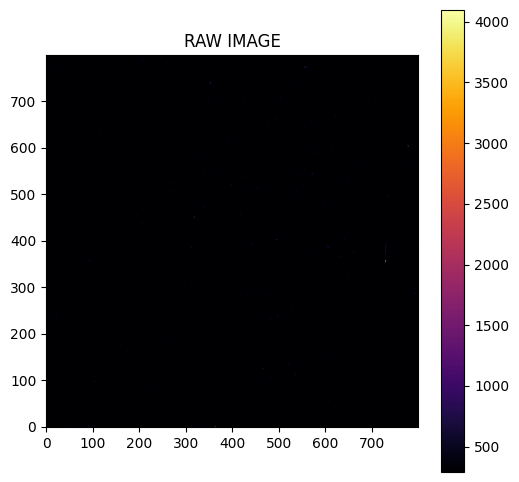

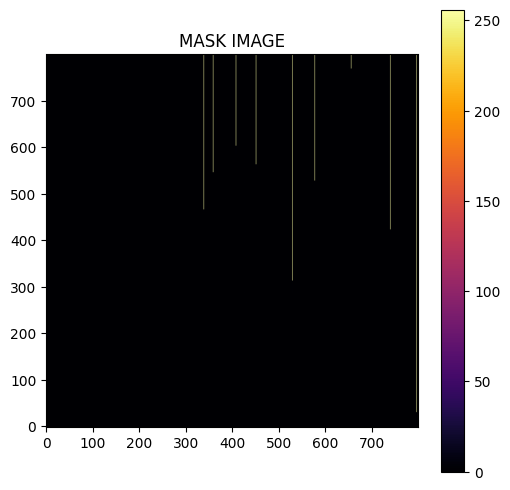

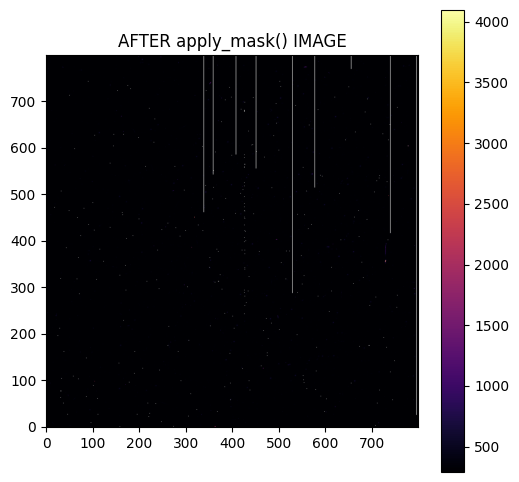

In [49]:
#adding normalisation to see result better
raw1 = per_norm(raw)
masked1 = apply_mask(raw1[0], mask[0])
masked = apply_mask(raw[0], mask[0])

show_image(raw[0], 'RAW IMAGE')
show_image(mask[0], 'MASK IMAGE')
show_image(masked, 'AFTER apply_mask() IMAGE')

### 3. Bias level with BLEVFILE

In [50]:
def parse_blev_file(filename, chip=0):
  
    data, _ = load_fits(filename)
    overscan = data[chip][9:790, 8:14]
    overscan[overscan == 0] = np.nan

    odd_vals = overscan[:, 1::2]
    even_vals = overscan[:, ::2]
    
    return np.mean(odd_vals), np.mean(even_vals)

  #---------------------------------------------------------------------

def apply_bias_corr(image, odd_mean, even_mean):
  corrected = image.copy()
  ny, nx = corrected.shape
    
  for x in range(nx):
    if x % 2 == 0:  # even index → odd physical column
      corrected[:, x] -= odd_mean
    else:            # odd index → even physical column
      corrected[:, x] -= even_mean
    
  return corrected


<!-- ### 4. Remove bias image with BIASFILE -->

In [51]:
def subtract_bias(image, bias):
    return image - bias

### 5. Subtract dark with DARKFILE 

In [52]:
def subtract_dark(image, dark, exptime):
    return image*exptime - dark #* exptime


### 6. Flatfield correction with FLATFILE

In [53]:
def apply_flat(image, flat):
    return image*flat